# VGG11: explicit per-layer mixed precision

Assign 8-bit or 4-bit signed activation/weight precision to named layers of a CIFAR-10 VGG11-BN checkpoint. Each layer owns an independent `Simulator`, its physical configuration, and programmed matrices. Set `layer_bits` to compare your assignment with uniform precision. All comparisons use a **6-bit ADC with saturation at 63**.

Install MemFast, torchvision, NumPy, Matplotlib, and Jupyter. Set `MEMFAST_CIFAR10_ROOT` and `MEMFAST_VGG_CHECKPOINT` to local CIFAR-10 test data and `cifar10_vgg11_bn-eaeebf42.pt` from the pytorch-cifar-models VGG release. Every comparison evaluates all **10,000 CIFAR-10 test images** by default (`MEMFAST_VGG_SAMPLES=0`). Choose CPU or CUDA in the settings cell; CUDA is recommended for the complete sweep. The saved prints and plots below come from actual execution.

In [2]:
import copy
import gc
import os
import time
from dataclasses import asdict, replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

from memfast import Config, Nonidealities, Simulator
from memfast.models import cifar_model
from memfast.nn import AnalogConv2d, AnalogLinear

SEED = 135
torch.manual_seed(SEED)
torch.set_num_threads(4)
device = torch.device(
    os.environ.get("MEMFAST_NOTEBOOK_DEVICE", "cuda:0" if torch.cuda.is_available() else "cpu")
)
data_root = Path(os.environ.get("MEMFAST_CIFAR10_ROOT", "data/cifar10"))
checkpoint = Path(
    os.environ.get(
        "MEMFAST_VGG_CHECKPOINT",
        str(Path(torch.hub.get_dir()) / "checkpoints/cifar10_vgg11_bn-eaeebf42.pt"),
    )
)
max_samples = int(os.environ.get("MEMFAST_VGG_SAMPLES", "0"))
batch_size = 8
if max_samples < 0:
    raise ValueError("Use a positive sample limit or 0 for the full test split")
if not checkpoint.is_file():
    raise FileNotFoundError(f"Set MEMFAST_VGG_CHECKPOINT to a real checkpoint: {checkpoint}")
print("Device:", device, "test split:", "full" if max_samples == 0 else max_samples)

Device: cuda:0 test split: full


## 1. Load and evaluate the original digital model

Use fixed ordered CIFAR-10 test inputs with the repository's evaluation normalization. Strict loading catches architecture or classifier mismatches. The table in the next cell lists the actual module paths used for layer selection; batch normalization, activations, pooling, and biases remain digital in all policies.

In [3]:
preprocess = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
    ]
)
dataset = datasets.CIFAR10(data_root, train=False, download=False, transform=preprocess)
sample_indices = list(range(len(dataset) if max_samples == 0 else min(max_samples, len(dataset))))
batches = list(DataLoader(Subset(dataset, sample_indices), batch_size=batch_size, shuffle=False))
targets = torch.cat([labels for _, labels in batches])
if max_samples == 0:
    assert len(dataset) == len(targets) == 10000
print(f"Evaluation examples: {len(targets)}; batches: {len(batches)}; batch size: {batch_size}")
model = cifar_model("vgg11_bn", num_classes=10).float().eval()
model.load_state_dict(torch.load(checkpoint, map_location="cpu", weights_only=True), strict=True)
layers = {
    name: layer
    for name, layer in model.named_modules()
    if isinstance(layer, (nn.Conv2d, nn.Linear))
}
weight_counts = {name: layer.weight.numel() for name, layer in layers.items()}
for name, layer in layers.items():
    print(f"{name:<16} {type(layer).__name__:<8} weight={tuple(layer.weight.shape)}")


@torch.inference_mode()
def evaluate(network):
    network.eval()
    logits = torch.cat([network(images.to(device)).cpu() for images, _ in batches])
    assert logits.shape == (len(targets), 10) and torch.isfinite(logits).all()
    predictions = logits.argmax(1)
    return dict(
        count=len(targets),
        correct=int((predictions == targets).sum()),
        top1=int((predictions == targets).sum()) / len(targets),
        cross_entropy=float(nn.functional.cross_entropy(logits, targets)),
        logits=logits,
    )


model.to(device)
digital_result = evaluate(model)
model.cpu()
print(
    f"Digital top-1: {100 * digital_result['top1']:.2f}% ({digital_result['correct']}/{len(targets)})"
)

Evaluation examples: 10000; batches: 1250; batch size: 8
features.0       Conv2d   weight=(64, 3, 3, 3)
features.4       Conv2d   weight=(128, 64, 3, 3)
features.8       Conv2d   weight=(256, 128, 3, 3)
features.11      Conv2d   weight=(256, 256, 3, 3)
features.15      Conv2d   weight=(512, 256, 3, 3)
features.18      Conv2d   weight=(512, 512, 3, 3)
features.22      Conv2d   weight=(512, 512, 3, 3)
features.25      Conv2d   weight=(512, 512, 3, 3)
classifier.0     Linear   weight=(512, 512)
classifier.3     Linear   weight=(512, 512)
classifier.6     Linear   weight=(10, 512)


Digital top-1: 92.78% (9278/10000)


## 2. Choose bits and ADC widths explicitly

Edit `layer_bits` below: every eligible module path must appear exactly once, with a value of 4 or 8. Here each value sets both activation bits and weight bits for that layer; the next layer independently requantizes its input. No global bit-width mutation or mixed-precision search is hidden in conversion.

Symmetric signed INT uses $q=\operatorname{clip}(\operatorname{round}(x/s),-Q,Q)$, $Q=2^{b-1}-1$, and $s=\max|x|/Q$. Thus reducing bits increases quantization steps. Quantization uses one scale per unfolded input vector/patch and one per output channel. All layers keep physical arrays at 64 x 64. The A8W8 baseline explicitly uses `input_slice=(1,)*8` and `weight_slice=(1,)*8`; a 4-bit layer uses `(1,)*4` for each. Every input and weight slice is one bit; no multibit slicing or other geometry is used.

`adc_bits` is the converter width, independent of activation/weight bits. `adc_by_layer` exposes the named per-layer configuration; every entry is set to 6 here to keep the converter identical across policies and slices. Changing activation/weight bits does not change the ADC width.

An ADC code is a rounded current count clipped to $0..(2^6-1)=0..63$. Sixty-four binary rows can produce an ideal count of 64; this experiment deliberately saturates that endpoint to 63. This is the same physical rule for every policy, including ideal devices. Programming is $G'=G\exp(0.02z)$ by default; ideal-device comparisons explicitly set write variation to zero and retain quantization and ADC saturation.

In [4]:
layer_bits = {
    "features.0": 8,
    "features.4": 8,
    "features.8": 4,
    "features.11": 4,
    "features.15": 4,
    "features.18": 4,
    "features.22": 4,
    "features.25": 4,
    "classifier.0": 4,
    "classifier.3": 4,
    "classifier.6": 8,
}
adc_bits = 6
adc_by_layer = {
    "features.0": 6,
    "classifier.6": 6,
}
physical_config = Config(
    activation_bits=8,
    weight_bits=8,
    input_slice=(1,) * 8,
    weight_slice=(1,) * 8,
    array_size=(64, 64),
    adc_bits=adc_bits,
    seed=SEED,
    input_quant_gran=(1, None),
    weight_quant_gran=(None, 1),
    nonidealities=Nonidealities(write_variation=0.02),
)
if set(layer_bits) != set(layers) or any(value not in (4, 8) for value in layer_bits.values()):
    raise ValueError("Assign exactly every eligible layer either 4 or 8 bits")
if set(adc_by_layer) - set(layers):
    raise ValueError("ADC overrides contain unknown layer names")
for name in layers:
    print(
        f"{name:<16} A{layer_bits[name]} W{layer_bits[name]} ADC={adc_by_layer.get(name, adc_bits)}"
    )

features.0       A8 W8 ADC=6
features.4       A8 W8 ADC=6
features.8       A4 W4 ADC=6
features.11      A4 W4 ADC=6
features.15      A4 W4 ADC=6
features.18      A4 W4 ADC=6
features.22      A4 W4 ADC=6
features.25      A4 W4 ADC=6
classifier.0     A4 W4 ADC=6
classifier.3     A4 W4 ADC=6
classifier.6     A8 W8 ADC=6


## 3. Build one simulator per layer

Build each policy from a copy of the digital model. Replace layers by name to assign their simulators, precision and physical settings. The seed and original layer name determine the programmed fields for each layout.

The construction check verifies that simulators are distinct objects and each mapped matrix uses the intended layer configuration. Biases remain digital. The `logical_weight_bits` total is an arithmetic storage proxy, $\sum_l n_l b_l$, excluding biases and digital layers.

In [5]:
def build_mixed_model(bits_by_layer, default_adc, overrides, write=0.02):
    if set(bits_by_layer) != set(layers) or any(
        bits not in (4, 8) for bits in bits_by_layer.values()
    ):
        raise ValueError("Every eligible layer needs an explicit 4-bit or 8-bit assignment")
    if set(overrides) - set(layers):
        raise ValueError("Unknown layer in ADC overrides")
    converted = copy.deepcopy(model).to(device).eval()
    engines = {}
    for name, bits in bits_by_layer.items():
        source = converted.get_submodule(name)
        config = replace(
            physical_config,
            activation_bits=bits,
            weight_bits=bits,
            input_slice=(1,) * bits,
            weight_slice=(1,) * bits,
            adc_bits=overrides.get(name, default_adc),
            nonidealities=Nonidealities(write_variation=write),
        )
        engine = Simulator(config, device=str(device))
        engines[name] = engine
        replacement = (
            AnalogConv2d(source, engine, name=name)
            if isinstance(source, nn.Conv2d)
            else AnalogLinear(source, engine, name=name)
        )
        parent_name, attribute = name.rsplit(".", 1)
        setattr(converted.get_submodule(parent_name), attribute, replacement)
        matrices = (
            list(replacement.matrices) if isinstance(replacement, AnalogConv2d) else [replacement]
        )
        assert all(matrix.simulator is engine and matrix.config == config for matrix in matrices)
    assert len({id(engine) for engine in engines.values()}) == len(layers)
    return converted.eval().requires_grad_(False), engines


user_model, user_engines = build_mixed_model(layer_bits, adc_bits, adc_by_layer)
user_result = evaluate(user_model)
user_configs = {name: asdict(engine.config) for name, engine in user_engines.items()}
print(
    f"User assignment: {100 * user_result['top1']:.2f}% top-1 ({user_result['correct']}/{user_result['count']})"
)
del user_model, user_engines
gc.collect()
if device.type == "cuda":
    torch.cuda.empty_cache()

User assignment: 92.36% top-1 (9236/10000)


## 4. Compare policies at a fixed ADC limit of 63

Declare five policies: uniform 8-bit, uniform 4-bit, the user-selected assignment, 8-bit first convolution/final head with other layers at 4-bit, and 8-bit feature extractor with a 4-bit classifier. Cross them with write variation {0, 0.02}, always using ADC6: **5 x 2 = 10 evaluations**, in addition to the digital baseline and the separate per-layer ADC configuration demonstration.

The grid uses ADC6 in every layer (`overrides={}`). The earlier user example uses `adc_by_layer`, also fixed to 6. Edit the named precision assignments to compare policies while retaining the common one-bit slices, 64 x 64 arrays and ADC saturation at 63.

In [6]:
policies = {
    "uniform8": {name: 8 for name in layers},
    "uniform4": {name: 4 for name in layers},
    "user": dict(layer_bits),
    "first-head8": {name: 8 if name in ("features.0", "classifier.6") else 4 for name in layers},
    "features8-head4": {name: 8 if name.startswith("features.") else 4 for name in layers},
}
adc_grid = (6,)
write_grid = (0.0, 0.02)
print("Declared policy/ADC/write points:", len(policies) * len(adc_grid) * len(write_grid))
for label, assignment in policies.items():
    logical_bits = sum(weight_counts[name] * bits for name, bits in assignment.items())
    average = logical_bits / sum(weight_counts.values())
    print(
        f"{label:<18} mean weight bits={average:.3f}; 8-bit layers={[name for name, bits in assignment.items() if bits == 8]}"
    )

Declared policy/ADC/write points: 10
uniform8           mean weight bits=8.000; 8-bit layers=['features.0', 'features.4', 'features.8', 'features.11', 'features.15', 'features.18', 'features.22', 'features.25', 'classifier.0', 'classifier.3', 'classifier.6']
uniform4           mean weight bits=4.000; 8-bit layers=[]
user               mean weight bits=4.033; 8-bit layers=['features.0', 'features.4', 'classifier.6']
first-head8        mean weight bits=4.003; 8-bit layers=['features.0', 'classifier.6']
features8-head4    mean weight bits=7.783; 8-bit layers=['features.0', 'features.4', 'features.8', 'features.11', 'features.15', 'features.18', 'features.22', 'features.25']


In [7]:
mixed_results = []
for label, assignment in policies.items():
    for adc in adc_grid:
        for write in write_grid:
            started = time.perf_counter()
            analog, engines = build_mixed_model(assignment, adc, overrides={}, write=write)
            result = evaluate(analog)
            result.update(
                policy=label,
                adc_bits=adc,
                write_variation=write,
                assignment=dict(assignment),
                configs={name: asdict(engine.config) for name, engine in engines.items()},
                logical_weight_bits=sum(
                    weight_counts[name] * bits for name, bits in assignment.items()
                ),
                agreement=float(
                    (result["logits"].argmax(1) == digital_result["logits"].argmax(1))
                    .float()
                    .mean()
                ),
                seconds=time.perf_counter() - started,
            )
            mixed_results.append(result)
            print(
                f"{len(mixed_results):02d}/{len(policies) * len(adc_grid) * len(write_grid)} {label:<18} ADC{adc} write={write:g} top1={100 * result['top1']:.2f}% ({result['correct']}/{result['count']})",
                flush=True,
            )
            del analog, engines
            gc.collect()
            if device.type == "cuda":
                torch.cuda.empty_cache()
assert len(mixed_results) == len(policies) * len(adc_grid) * len(write_grid)
assert all(result["count"] == len(targets) for result in mixed_results)

01/10 uniform8           ADC6 write=0 top1=92.79% (9279/10000)


02/10 uniform8           ADC6 write=0.02 top1=92.79% (9279/10000)


03/10 uniform4           ADC6 write=0 top1=91.52% (9152/10000)


04/10 uniform4           ADC6 write=0.02 top1=91.52% (9152/10000)


05/10 user               ADC6 write=0 top1=92.36% (9236/10000)


06/10 user               ADC6 write=0.02 top1=92.36% (9236/10000)


07/10 first-head8        ADC6 write=0 top1=91.92% (9192/10000)


08/10 first-head8        ADC6 write=0.02 top1=91.92% (9192/10000)


09/10 features8-head4    ADC6 write=0 top1=92.81% (9281/10000)


10/10 features8-head4    ADC6 write=0.02 top1=92.81% (9281/10000)


## 5. Inspect the precision map and measured accuracy

The first panel shows the per-layer precision assignment. The other panels compare all policies at the same ADC6 limit of 63, with a shared vertical scale. Ideal-device CIM retains quantization and ADC saturation with programming variation set to zero.

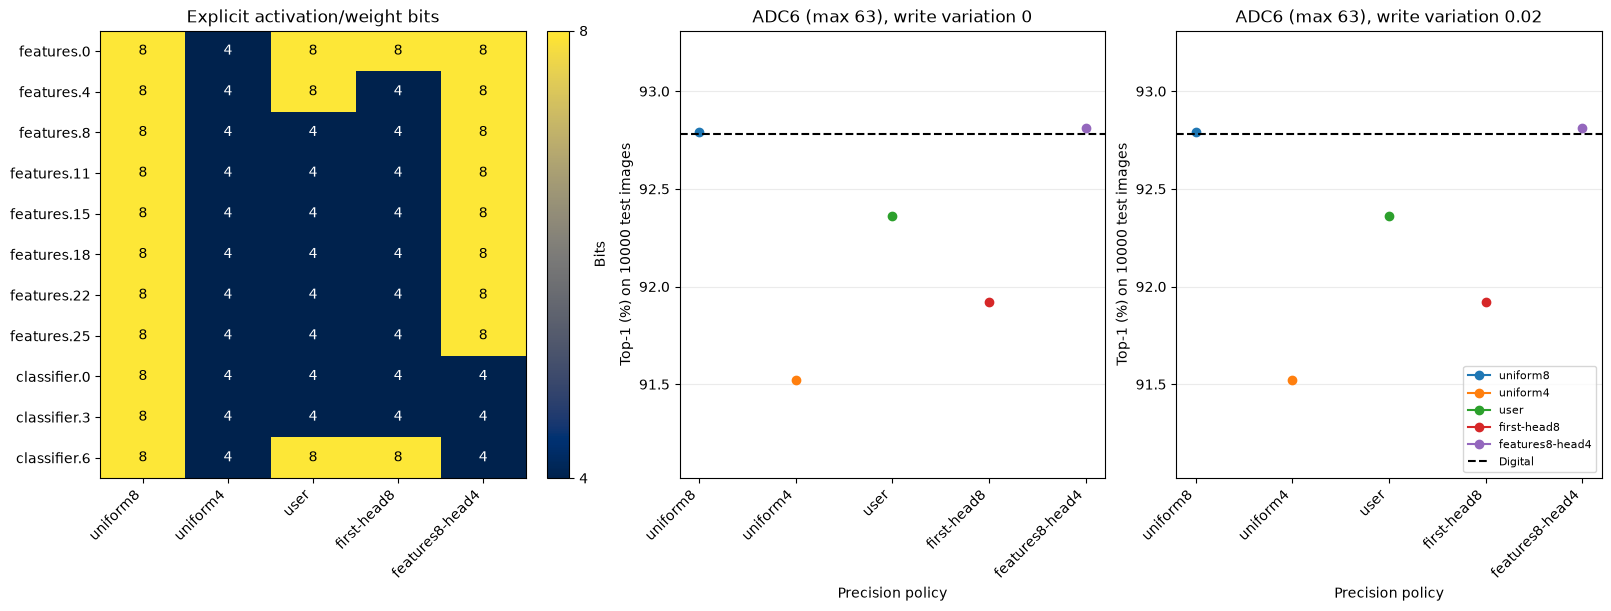

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6), constrained_layout=True)
policy_names = list(policies)
precision_map = np.array([[policies[label][name] for label in policy_names] for name in layers])
image = axes[0].imshow(precision_map, vmin=4, vmax=8, cmap="cividis", aspect="auto")
axes[0].set_xticks(range(len(policy_names)), policy_names, rotation=45, ha="right")
axes[0].set_yticks(range(len(layers)), list(layers))
axes[0].set_title("Explicit activation/weight bits")
for row in range(len(layers)):
    for column in range(len(policy_names)):
        value = precision_map[row, column]
        axes[0].text(
            column,
            row,
            str(value),
            ha="center",
            va="center",
            color="black" if value == 8 else "white",
        )
fig.colorbar(image, ax=axes[0], ticks=[4, 8], label="Bits")
accuracy_values = [100 * item["top1"] for item in mixed_results] + [100 * digital_result["top1"]]
accuracy_limits = (max(0, min(accuracy_values) - 0.5), min(100, max(accuracy_values) + 0.5))
for ax, write in zip(axes[1:], write_grid):
    for policy_index, label in enumerate(policy_names):
        measured = [
            item
            for item in mixed_results
            if item["policy"] == label and item["write_variation"] == write
        ]
        ax.plot(
            [policy_index] * len(measured),
            [100 * item["top1"] for item in measured],
            marker="o",
            label=label,
        )
    ax.axhline(100 * digital_result["top1"], color="black", linestyle="--", label="Digital")
    ax.set(
        xlabel="Precision policy",
        ylabel=f"Top-1 (%) on {len(targets)} test images",
        title=f"ADC6 (max 63), write variation {write:g}",
        ylim=accuracy_limits,
    )
    ax.set_xticks(range(len(policy_names)), policy_names, rotation=45, ha="right")
    ax.grid(axis="y", alpha=0.25)
axes[2].legend(fontsize=8)
plt.show()

### Observed execution

The complete sweep evaluates all **10,000 test images for each of the 10 policy/write configurations**, as well as the digital model and the per-layer ADC configuration example. All mapped layers use ADC6 with maximum count 63. Inputs are test indices 0..9999, batch size 8, seed 135, default scheduling and 64 x 64 arrays. Each mapped layer has its own simulator. The following cell prints the measured write0.02 results and the range over the complete grid.

Edit `layer_bits` and `adc_by_layer` to evaluate your own precision assignment. These results use the checkpoint, programming seed and device parameters shown above.

In [9]:
print(f"Full comparison: {len(mixed_results)} grid points, {len(targets)} test images per point")
print(f"{'ADC6 (max 63), write .02':<24} {'Correct / total':>18} {'Top-1 (%)':>12}")
print(
    f"{'Digital':<24} {digital_result['correct']:>8}/{digital_result['count']:<9} {100 * digital_result['top1']:>11.2f}"
)
for item in mixed_results:
    if item["adc_bits"] == 6 and item["write_variation"] == 0.02:
        print(
            f"{item['policy']:<24} {item['correct']:>8}/{item['count']:<9} {100 * item['top1']:>11.2f}"
        )
print(
    f"Complete-grid top-1 range: {100 * min(item['top1'] for item in mixed_results):.2f}% to {100 * max(item['top1'] for item in mixed_results):.2f}%"
)

Full comparison: 10 grid points, 10000 test images per point
ADC6 (max 63), write .02    Correct / total    Top-1 (%)
Digital                      9278/10000           92.78
uniform8                     9279/10000           92.79
uniform4                     9152/10000           91.52
user                         9236/10000           92.36
first-head8                  9192/10000           91.92
features8-head4              9281/10000           92.81
Complete-grid top-1 range: 91.52% to 92.81%
